Upload your ZIP file containing the healthcare headlines dataset.


Saving Health-Related-Headlines-Datasets-for-Natural-Language-Processing-master.zip to Health-Related-Headlines-Datasets-for-Natural-Language-Processing-master.zip

Loaded file: Health_Related_Headlines_Dataset.csv
Dataset shape: (39405, 5)
Columns: ['Date', 'Source', 'Headlines', 'Teaser', 'Category']

First five rows:


,Date,Source,Headlines,Teaser,Category
0,"January, 1970",Medscape Special Reports,Special Report: Adult Vaccines -- New ACIP Rec...,New recommendations for already approved vacci...,Immunization
1,"January, 1970",Medscape Medical News,Combined Internet and Telephone Intervention M...,"In a randomized trial, combined Internet and t...",Substance Abuse and Addiction
2,"April, 1997",Medscape Psychiatry & Mental Health eJournal [TM],Link Between Parental Alcoholism and Childhood...,It is proposed that depressed children identif...,Substance Abuse and Addiction
3,"November, 1997",Medscape Psychiatry & Mental Health eJournal [TM],Methadone Dose in the Treatment of Opiate Depe...,The epidemic of heroin abuse within the US has...,Substance Abuse and Addiction
4,"March, 2000",Medscape Medical News,Magnet Treatment Had No Beneficial Effect on P...,A small study using one variety of magnet for ...,Pain Management



Text columns used: ['Headlines', 'Teaser']
Usable text records: 39405

Cleaning text...

Original and cleaned text samples:


,raw_text,cleaned_text
0,Special Report: Adult Vaccines -- New ACIP Rec...,special report adult vaccine new acip recommen...
1,Combined Internet and Telephone Intervention M...,combined internet telephone intervention may f...
2,Link Between Parental Alcoholism and Childhood...,link parental alcoholism childhood mood disord...
3,Methadone Dose in the Treatment of Opiate Depe...,methadone dose treatment opiate dependence epi...
4,Magnet Treatment Had No Beneficial Effect on P...,magnet treatment no beneficial effect patient ...
5,Ask the Experts - Investigational Agents for M...,ask expert investigational agent mesothelioma ...
6,Estrogen Replacement May Negate the Benefits o...,estrogen replacement may negate benefit growth...
7,MEDLINE Abstracts: Thalidomide Clinical Trials...,medline abstract thalidomide clinical trial re...
8,IRB/FDA Requirements Relevant to HIV/AIDS Clin...,irb fda requirement relevant hiv aid clinical ...
9,HIV Clinical Trials in Correctional Settings: ...,hiv clinical trial correctional setting right ...



Top 20 frequent words:


,Word,Frequency
0,patient,12973
1,new,7995
2,risk,7630
3,study,6930
4,drug,6566
5,treatment,5779
6,cancer,5628
7,pain,5613
8,use,4993
9,may,4854


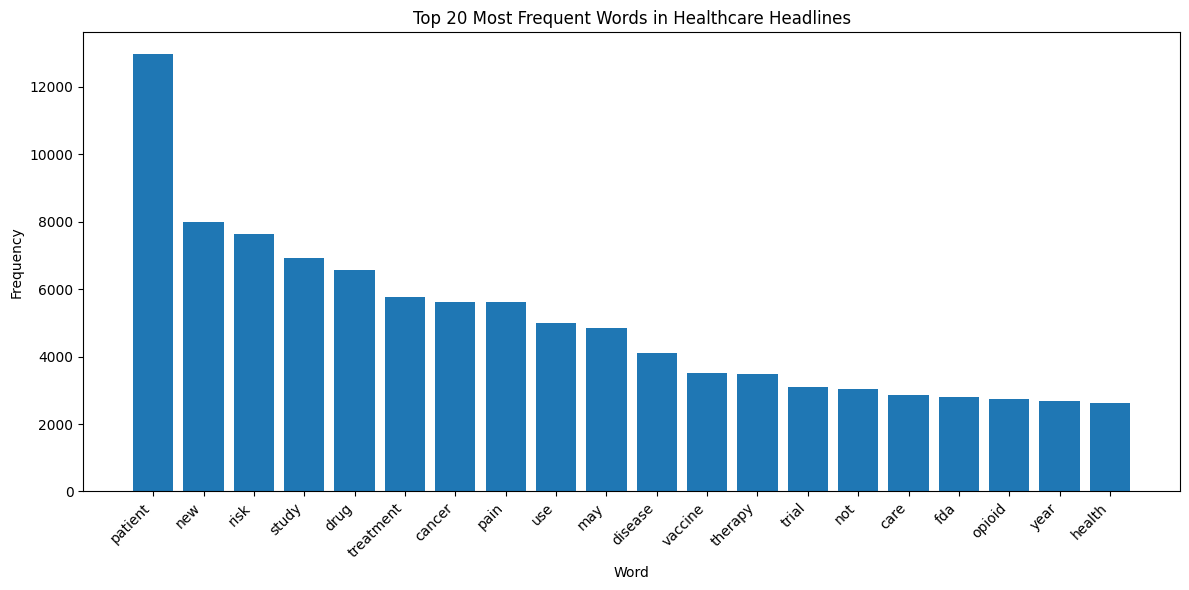

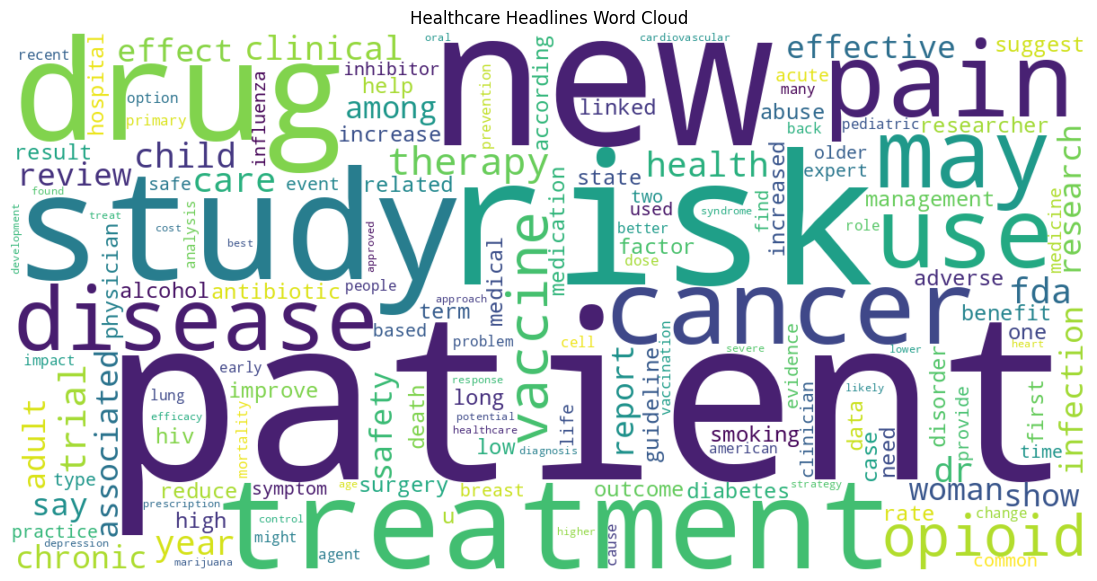


Creating document-term matrix...
Document-term matrix shape: (39405, 5000)
Training LDA model...

TOP 5 WORDS PER TOPIC
Topic 1: drug, opioid, physician, medical, use
Topic 2: vaccine, child, infection, influenza, vaccination
Topic 3: patient, dr, pain, care, treatment
Topic 4: drug, fda, safety, treatment, approved
Topic 5: patient, surgery, pain, study, hospital
Topic 6: pain, woman, patient, cancer, study
Topic 7: cancer, patient, trial, therapy, treatment
Topic 8: risk, patient, study, use, diabetes


,Topic,Top 5 Words
0,1,"drug, opioid, physician, medical, use"
1,2,"vaccine, child, infection, influenza, vaccination"
2,3,"patient, dr, pain, care, treatment"
3,4,"drug, fda, safety, treatment, approved"
4,5,"patient, surgery, pain, study, hospital"
5,6,"pain, woman, patient, cancer, study"
6,7,"cancer, patient, trial, therapy, treatment"
7,8,"risk, patient, study, use, diabetes"



Number of documents per dominant topic:


,Topic,Document Count
0,1,5385
1,2,4224
2,3,5514
3,4,3363
4,5,4413
5,6,3787
6,7,6186
7,8,6533


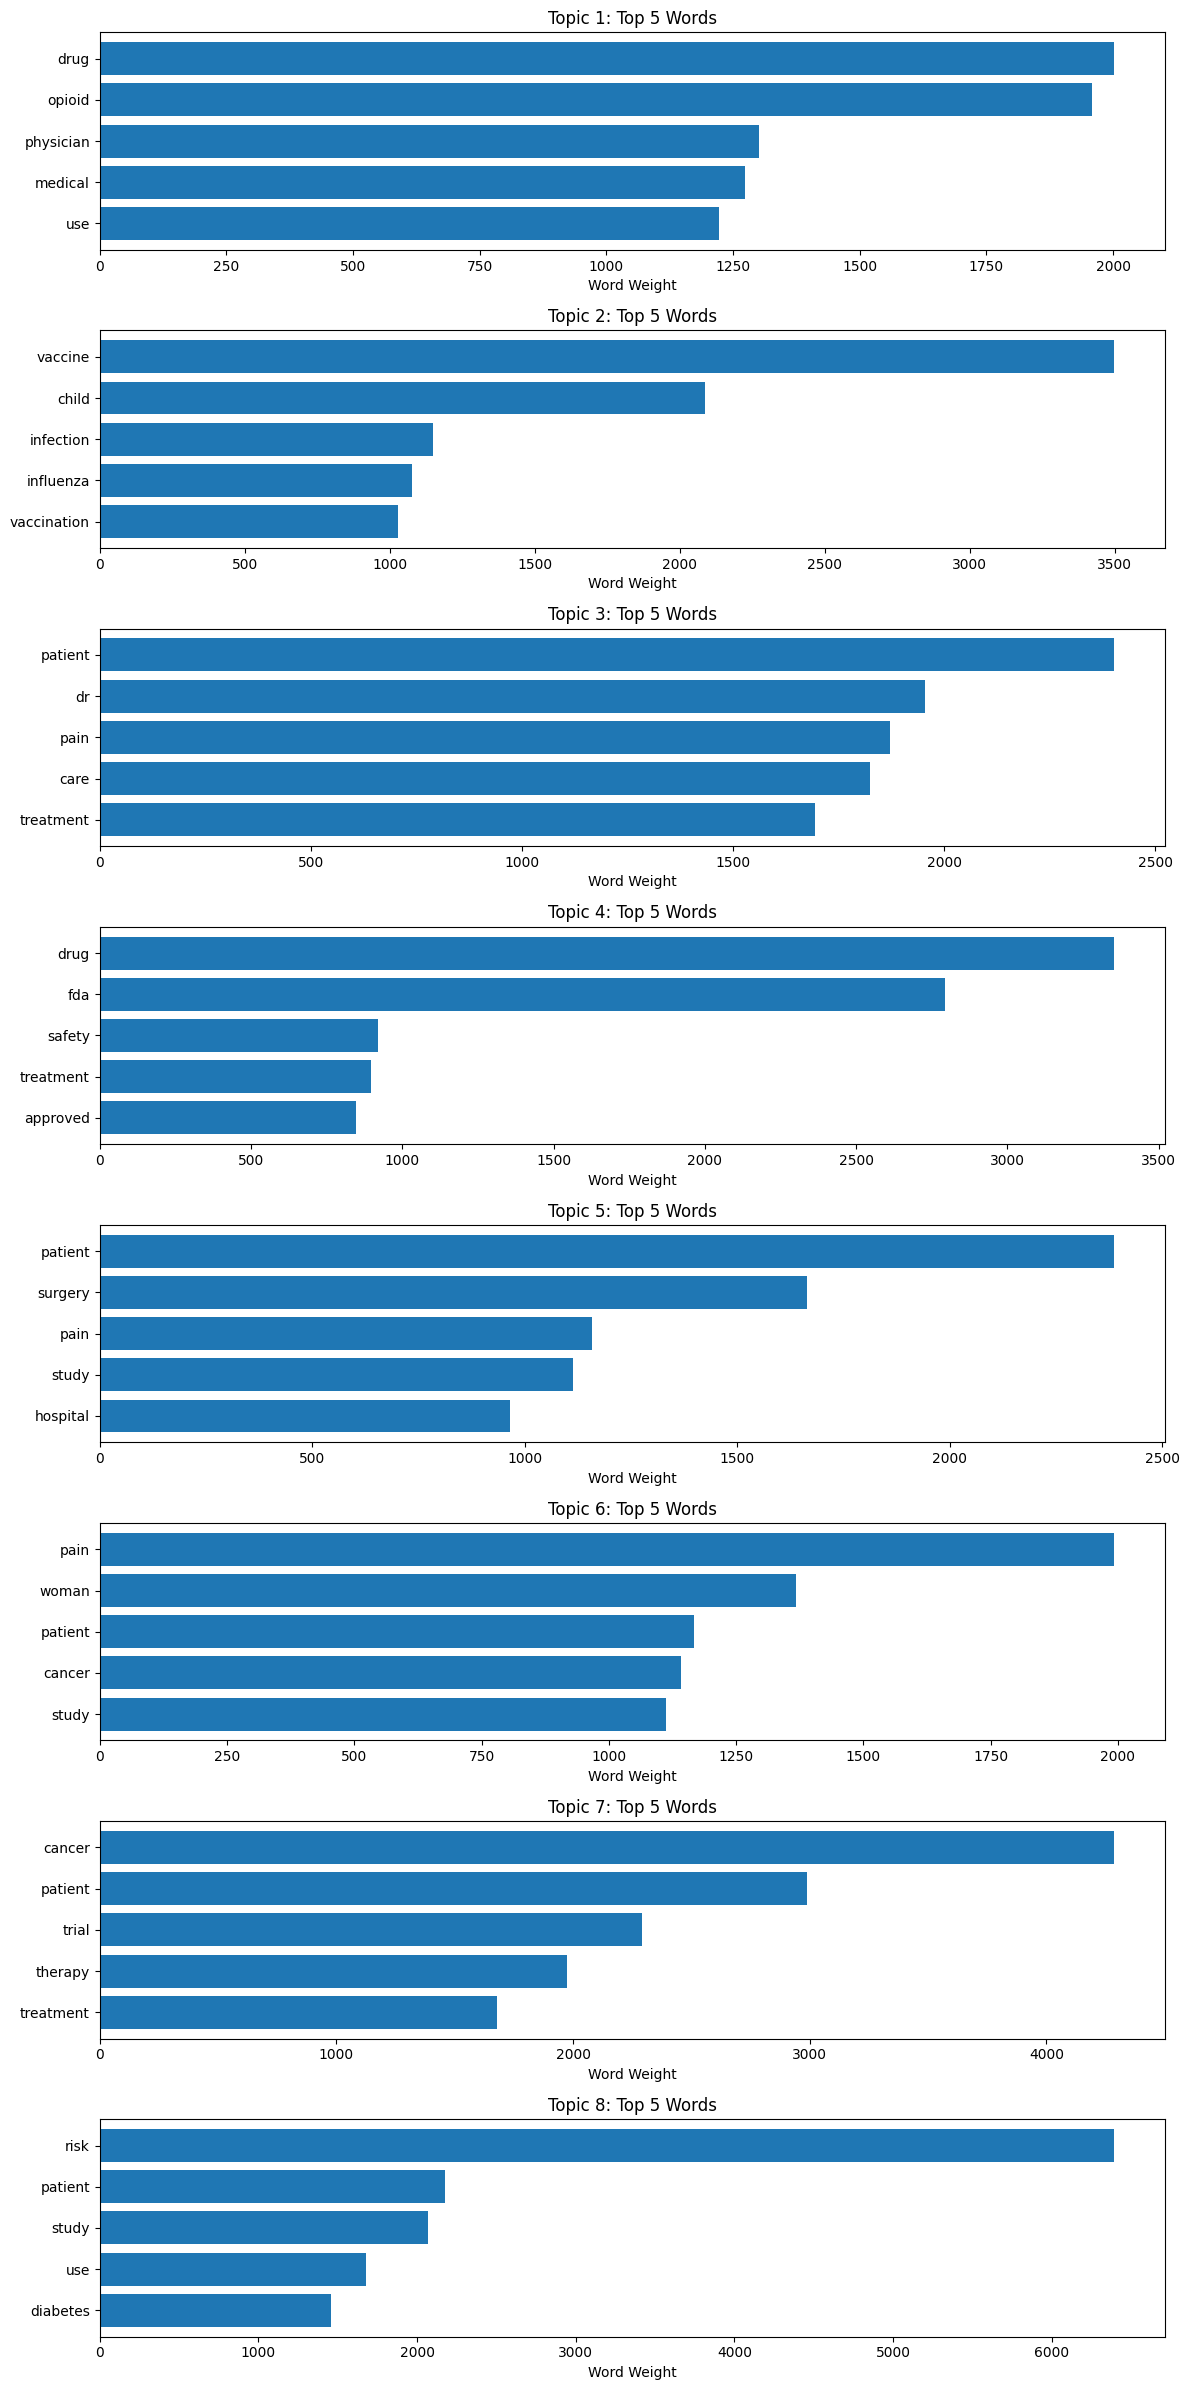


Preparing interactive pyLDAvis visualization...

All tasks completed.
Results saved in: /content/lab8_results


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

!pip -q install wordcloud nltk pyLDAvis

import os
import re
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
import pyLDAvis
import pyLDAvis.lda_model

from google.colab import files
from collections import Counter
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

warnings.filterwarnings("ignore")
np.random.seed(42)

# ---------------- TASK 1: DATA LOADING ----------------

print("Upload your ZIP file containing the healthcare headlines dataset.")
uploaded = files.upload()

zip_files = [f for f in uploaded if f.lower().endswith(".zip")]
if not zip_files:
    raise ValueError("Please upload a ZIP file.")

zip_path = os.path.join("/content", zip_files[0])
extract_dir = "/content/healthcare_dataset"
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

csv_files = [
    os.path.join(root, name)
    for root, _, names in os.walk(extract_dir)
    for name in names
    if name.lower().endswith(".csv")
]

if not csv_files:
    raise FileNotFoundError("No CSV file found inside the ZIP.")

# Prefer the consolidated dataset rather than individual topic files
main_csv = [
    f for f in csv_files
    if "health_related_headlines_dataset" in os.path.basename(f).lower()
]
csv_path = main_csv[0] if main_csv else max(csv_files, key=os.path.getsize)

df = pd.read_csv(csv_path, low_memory=False)
df.columns = [str(c).strip() for c in df.columns]

print("\nLoaded file:", os.path.basename(csv_path))
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nFirst five rows:")
display(df.head())

# Select relevant text columns automatically
column_map = {c.lower().strip(): c for c in df.columns}
text_columns = []

for candidate in ["headlines", "headline", "title", "teaser", "description", "text", "content"]:
    if candidate in column_map:
        text_columns.append(column_map[candidate])

if not text_columns:
    text_columns = [
        c for c in df.columns
        if df[c].dtype == "object"
        and df[c].dropna().astype(str).str.len().mean() > 15
    ]

if not text_columns:
    raise ValueError("No suitable text column was detected.")

print("\nText columns used:", text_columns)

df["raw_text"] = (
    df[text_columns].fillna("").astype(str).agg(" ".join, axis=1)
    .str.strip()
)
df = df[df["raw_text"].str.len() > 0].copy()
df = df.reset_index(drop=True)

print("Usable text records:", len(df))

# ---------------- TASK 1: PREPROCESSING ----------------

nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

# Keep negations because they may be meaningful in healthcare text
stop_words.discard("no")
stop_words.discard("not")
stop_words.discard("nor")

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = re.findall(r"\b[a-z]+\b", text)
    tokens = [
        lemmatizer.lemmatize(token)
        for token in tokens
        if token not in stop_words and len(token) > 1
    ]
    return " ".join(tokens)

print("\nCleaning text...")
df["cleaned_text"] = df["raw_text"].apply(clean_text)
df = df[df["cleaned_text"].str.strip().ne("")].reset_index(drop=True)

print("\nOriginal and cleaned text samples:")
display(df[["raw_text", "cleaned_text"]].head(10))

# ---------------- TASK 2: WORD FREQUENCY ----------------

all_tokens = " ".join(df["cleaned_text"]).split()
word_counts = Counter(all_tokens)

frequency_df = pd.DataFrame(
    word_counts.most_common(20),
    columns=["Word", "Frequency"]
)

print("\nTop 20 frequent words:")
display(frequency_df)

plt.figure(figsize=(12, 6))
plt.bar(frequency_df["Word"], frequency_df["Frequency"])
plt.title("Top 20 Most Frequent Words in Healthcare Headlines")
plt.xlabel("Word")
plt.ylabel("Frequency")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=150,
    collocations=False,
    random_state=42
).generate(" ".join(all_tokens))

plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Healthcare Headlines Word Cloud")
plt.show()

# ---------------- TASK 3: LDA TOPIC MODELLING ----------------

print("\nCreating document-term matrix...")

N_TOPICS = 8
MAX_FEATURES = 5000

vectorizer = CountVectorizer(
    max_features=MAX_FEATURES,
    min_df=5,
    max_df=0.90,
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b"
)

dtm = vectorizer.fit_transform(df["cleaned_text"])
feature_names = vectorizer.get_feature_names_out()

print("Document-term matrix shape:", dtm.shape)

if dtm.shape[1] < N_TOPICS:
    raise ValueError(
        "Not enough vocabulary for topic modelling. "
        "Check the text column and preprocessing results."
    )

lda_model = LatentDirichletAllocation(
    n_components=N_TOPICS,
    random_state=42,
    learning_method="batch",
    max_iter=10,
    n_jobs=-1,
    evaluate_every=-1
)

print("Training LDA model...")
lda_model.fit(dtm)

print("\nTOP 5 WORDS PER TOPIC")

topic_rows = []

for topic_idx, topic in enumerate(lda_model.components_):
    top_indices = topic.argsort()[-5:][::-1]
    top_words = [feature_names[i] for i in top_indices]

    print(f"Topic {topic_idx + 1}: {', '.join(top_words)}")

    topic_rows.append({
        "Topic": topic_idx + 1,
        "Top 5 Words": ", ".join(top_words)
    })

topics_df = pd.DataFrame(topic_rows)
display(topics_df)

# Dominant topic for each document
topic_probabilities = lda_model.transform(dtm)
df["dominant_topic"] = topic_probabilities.argmax(axis=1) + 1

print("\nNumber of documents per dominant topic:")
display(
    df["dominant_topic"]
    .value_counts()
    .sort_index()
    .rename_axis("Topic")
    .reset_index(name="Document Count")
)

# Visualize top words for each topic
fig, axes = plt.subplots(
    N_TOPICS, 1, figsize=(12, 3 * N_TOPICS)
)

for i, ax in enumerate(axes):
    topic = lda_model.components_[i]
    top_indices = topic.argsort()[-5:][::-1]
    words = [feature_names[j] for j in top_indices]
    weights = [topic[j] for j in top_indices]

    ax.barh(words[::-1], weights[::-1])
    ax.set_title(f"Topic {i + 1}: Top 5 Words")
    ax.set_xlabel("Word Weight")

plt.tight_layout()
plt.show()

# ---------------- pyLDAvis VISUALIZATION ----------------

print("\nPreparing interactive pyLDAvis visualization...")

vis = pyLDAvis.lda_model.prepare(
    lda_model,
    dtm,
    vectorizer,
    mds="pcoa",
    sort_topics=False
)

pyLDAvis.display(vis)

# ---------------- SAVE OUTPUTS ----------------

output_dir = "/content/lab8_results"
os.makedirs(output_dir, exist_ok=True)

df.to_csv(
    os.path.join(output_dir, "cleaned_healthcare_headlines.csv"),
    index=False
)

frequency_df.to_csv(
    os.path.join(output_dir, "top_20_word_frequencies.csv"),
    index=False
)

topics_df.to_csv(
    os.path.join(output_dir, "lda_topics.csv"),
    index=False
)

pyLDAvis.save_html(
    vis,
    os.path.join(output_dir, "lda_visualization.html")
)

with open(os.path.join(output_dir, "assignment_summary.txt"), "w") as f:
    f.write("LAB ASSIGNMENT 8: HEALTHCARE TEXT ANALYSIS\n\n")
    f.write(f"Dataset file: {os.path.basename(csv_path)}\n")
    f.write(f"Documents analyzed: {len(df)}\n")
    f.write(f"Vocabulary size: {dtm.shape[1]}\n")
    f.write(f"Number of topics: {N_TOPICS}\n\n")
    f.write("Top 5 words per topic:\n")
    for _, row in topics_df.iterrows():
        f.write(f"{row['Topic']}: {row['Top 5 Words']}\n")

import shutil
archive_path = shutil.make_archive(
    "/content/lab8_results", "zip", output_dir
)

print("\nAll tasks completed.")
print("Results saved in:", output_dir)
print("Downloading output files...")
files.download(archive_path)
